# TP1 — Risque de Bayes, sur-apprentissage, évaluation (corrigé)
**CNFSDP — Introduction au Machine Learning** · L3 S5 · 2026-2027 · Rois Céti DIMBAMBA · chapitre 1 · 30 min en salle

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rdimbamba/ml-cnfsdp/blob/main/notebooks/corriges/TP1_corrige.ipynb)

Partie A : régression, sur-apprentissage d'un arbre et variance. Partie B : classification, erreur de Bayes, intervalle de confiance, validation croisée, ROC.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_curve, roc_auc_score
VERT, OR, GRIS = "#126B2A", "#B8860B", "#8A8A8A"   # couleurs du cours

## Partie A — Régression : $Y=\sin(2\pi X)+\varepsilon$, $X\sim\mathcal U[0,1]$, $\sigma=0{,}3$
Ici le meilleur prédicteur est $f^*(x)=\sin(2\pi x)$ et l'erreur irréductible vaut $R^*=\sigma^2=0{,}09$ (modèle signal + bruit du cours).

In [2]:
rng = np.random.default_rng(1)
sigma = 0.3
def simuler_reg(n):
    X = rng.uniform(0, 1, (n, 1))
    return X, np.sin(2 * np.pi * X[:, 0]) + sigma * rng.standard_normal(n)

X, y = simuler_reg(200)        # apprentissage
Xt, yt = simuler_reg(5_000)    # test

### Question 1 — Risques d'apprentissage et test selon la profondeur
Pour chaque profondeur $p=1,\dots,15$, ajuster `DecisionTreeRegressor(max_depth=p)` sur $(X,y)$, calculer l'erreur quadratique moyenne sur l'apprentissage et sur le test, puis tracer les deux courbes avec la droite $R^*=\sigma^2$.

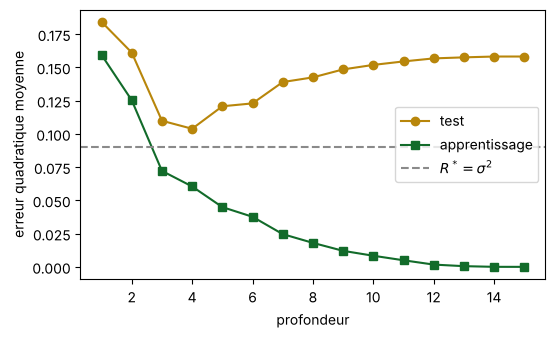

profondeur optimale : 4 | risque test : 0.1039 | R* : 0.09


In [3]:
prof = range(1, 16)
err_app, err_test = [], []
for p in prof:
    f = DecisionTreeRegressor(max_depth=p, random_state=0).fit(X, y)
    err_app.append(np.mean((f.predict(X) - y) ** 2))
    err_test.append(np.mean((f.predict(Xt) - yt) ** 2))

plt.figure(figsize=(6, 3.5))
plt.plot(prof, err_test, color=OR, marker="o", label="test")
plt.plot(prof, err_app, color=VERT, marker="s", label="apprentissage")
plt.axhline(sigma ** 2, color=GRIS, ls="--", label="$R^*=\\sigma^2$")
plt.xlabel("profondeur"); plt.ylabel("erreur quadratique moyenne"); plt.legend(); plt.show()
p_opt = list(prof)[int(np.argmin(err_test))]
print("profondeur optimale :", p_opt, "| risque test :", round(min(err_test), 4), "| R* :", sigma ** 2)

**À commenter :** pourquoi l'erreur d'apprentissage tend-elle vers 0 ? Pourquoi le risque test ne descend-il jamais sous $\sigma^2$ ?

### Question 2 — Variance d'un arbre profond
Tirer 20 échantillons bootstrap de $(X,y)$ (tirage avec remise de 200 indices). Sur chacun, ajuster un arbre de profondeur 15 et un arbre de profondeur 3, et tracer leurs prédictions sur une grille de $[0,1]$. Estimer la variance moyenne des prédictions dans les deux cas.

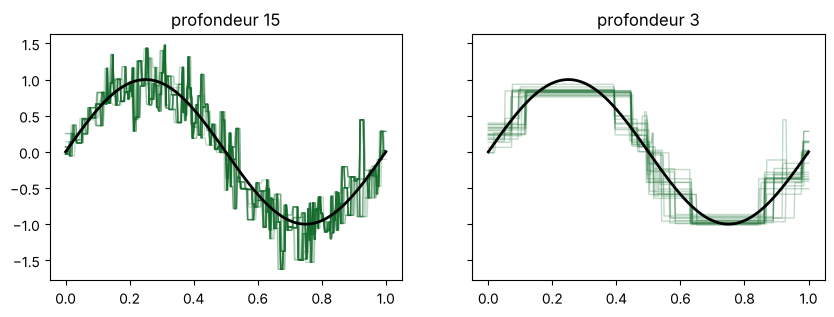

profondeur 3 : variance moyenne des prédictions = 0.0228
profondeur 15 : variance moyenne des prédictions = 0.0367


In [4]:
grille = np.linspace(0, 1, 400)[:, None]
pred = {3: [], 15: []}
for b in range(20):
    idx = rng.integers(0, len(y), len(y))          # échantillon bootstrap
    for p in pred:
        f = DecisionTreeRegressor(max_depth=p, random_state=0).fit(X[idx], y[idx])
        pred[p].append(f.predict(grille))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, p in zip(axes, [15, 3]):
    for courbe in pred[p]:
        ax.plot(grille[:, 0], courbe, color=VERT, alpha=0.25, lw=1)
    ax.plot(grille[:, 0], np.sin(2 * np.pi * grille[:, 0]), color="black", lw=2)
    ax.set_title(f"profondeur {p}")
plt.show()
for p in [3, 15]:
    print(f"profondeur {p} : variance moyenne des prédictions = {np.array(pred[p]).var(axis=0).mean():.4f}")

## Partie B — Classification : mélange gaussien du cours
$\P(Y=1)=\frac12$, $X\mid Y=k\sim\mathcal N_2(1{,}5\,k\,(1,1), I_2)$. Le classifieur de Bayes prédit 1 si $x_1+x_2>1{,}5$, et son erreur vaut $R^*=\Phi(-1{,}5/\sqrt2)\approx0{,}144$.

In [5]:
rng = np.random.default_rng(0)
def simuler_cl(n):
    y = rng.integers(0, 2, n)
    return rng.standard_normal((n, 2)) + 1.5 * y[:, None], y

X, y = simuler_cl(1_000)
Xt, yt = simuler_cl(10_000)
R_star = norm.cdf(-1.5 / np.sqrt(2))

### Questions 3 et 4 — Taux d'erreur test et intervalles de confiance
Comparer les taux d'erreur test de la régression logistique, d'un arbre de profondeur illimitée et du classifieur de Bayes à $R^*\approx0{,}144$. Donner pour chacun l'intervalle de confiance à 95 % : $\hat p\pm1{,}96\sqrt{\hat p(1-\hat p)/m}$.

In [6]:
m = len(yt)
def intervalle(p):                                   # IC à 95 % d'une proportion
    r = 1.96 * np.sqrt(p * (1 - p) / m)
    return p - r, p + r
modeles = {"logistique": LogisticRegression(), "arbre profond": DecisionTreeClassifier(random_state=0)}
for nom, f in modeles.items():
    err = np.mean(f.fit(X, y).predict(Xt) != yt)
    a, b = intervalle(err)
    print(f"{nom:14s}: {err:.4f}  [{a:.4f} ; {b:.4f}]")
err_bayes = np.mean((Xt.sum(axis=1) > 1.5) != yt)
a, b = intervalle(err_bayes)
print(f"{'Bayes':14s}: {err_bayes:.4f}  [{a:.4f} ; {b:.4f}]  | R* = {R_star:.4f}")

logistique    : 0.1476  [0.1406 ; 0.1546]
arbre profond : 0.2049  [0.1970 ; 0.2128]
Bayes         : 0.1445  [0.1376 ; 0.1514]  | R* = 0.1444


### Question 5 — Validation croisée et courbe ROC
Choisir la profondeur d'un arbre parmi $1,\dots,10$ par validation croisée à 5 blocs sur $(X,y)$, réentraîner sur tout $(X,y)$, puis tracer la courbe ROC sur le test et calculer l'AUC. Vérifier que l'AUC coïncide avec la statistique de Mann-Whitney.

profondeur choisie : 3 | taux de bonnes classifications en CV : 0.843
AUC : 0.8898 | Mann-Whitney : 0.8898


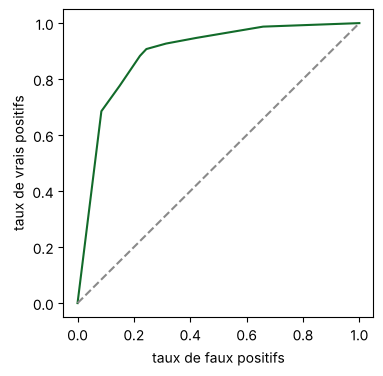

In [7]:
scores = [cross_val_score(DecisionTreeClassifier(max_depth=p, random_state=0), X, y, cv=5).mean()
          for p in range(1, 11)]
p_cv = int(np.argmax(scores)) + 1
print("profondeur choisie :", p_cv, "| taux de bonnes classifications en CV :", round(max(scores), 4))

f = DecisionTreeClassifier(max_depth=p_cv, random_state=0).fit(X, y)   # réentraînement
s = f.predict_proba(Xt)[:, 1]
fpr, tpr, _ = roc_curve(yt, s)
auc = roc_auc_score(yt, s)
pos, neg = s[yt == 1], s[yt == 0]
mw = np.mean(pos[:, None] > neg[None, :]) + 0.5 * np.mean(pos[:, None] == neg[None, :])  # ex aequo comptés 1/2
print("AUC :", round(auc, 4), "| Mann-Whitney :", round(mw, 4))
plt.figure(figsize=(4, 4)); plt.plot(fpr, tpr, color=VERT); plt.plot([0, 1], [0, 1], color=GRIS, ls="--")
plt.xlabel("taux de faux positifs"); plt.ylabel("taux de vrais positifs"); plt.show()

**Remarque.** Un arbre produit des scores constants par feuille, donc beaucoup d'ex aequo : la statistique de Mann-Whitney compte alors les égalités pour moitié, ce qui redonne exactement l'AUC calculée par scikit-learn.